# **Proyek Analisis Data: Persebaran dan Perilaku Pembelian Ulang Pelanggan E-Commerce Olist (Brasil)**
- **Nama:** Nabil Daffa Athalasyah

- **Email:** athalasyahnabil@gmail.com

- **ID Dicoding:** nabdaff95


## **Daftar Isi**
- [Menentukan Pertanyaan Bisnis](#menentukan-pertanyaan-bisnis)
- [Menyiapkan semua library yang dibutuhkan](#menyiapkan-semua-library-yang-dibutuhkan)
- [Data Wrangling](#data-wrangling)
- [Exploratory Data Analysis (EDA)](#exploratory-data-analysis-eda)
- [Visualization & Explanatory Analysis](#visualization--explanatory-analysis)
- [Analisis Lanjutan](#analisis-lanjutan)
- [Conclusion & Recommendation](#conclusion--recommendation)

## **Menentukan Pertanyaan Bisnis**

**Latar belakang:**

Olist merupakan marketplace Brasil yang menghubungkan penjual kecil dengan pembeli di seluruh negeri. Dataset yang dipakai adalah Brazilian E-Commerce Public Dataset by Olist (file `olist_customers_dataset.csv`) yang berisi data pelanggan dan lokasinya untuk pesanan periode 2016-2018. Analisis ini fokus pada dua hal: **di mana pelanggan berada dan seberapa sering mereka berbelanja lagi**.

**Pertanyaan bisnis:**

1. Pada periode 2016-2018, **5 state mana** di Brasil yang memiliki jumlah pelanggan unik terbanyak, dan **berapa persen** kontribusinya terhadap seluruh pelanggan Olist, sehingga tim logistik dapat memprioritaskan penempatan pusat distribusi?
2. Pada periode 2016-2018, **10 kota mana** yang memiliki pelanggan unik terbanyak, **berapa jumlah pelanggan unik tiap kota**, dan **berapa persen** kontribusi totalnya, sehingga tim pemasaran dapat menentukan kota target kampanye lokal?
3. Pada periode 2016-2018, **berapa persentase pelanggan repeat** (melakukan 2 order atau lebih) di tiap region Brasil dibandingkan rata-rata nasional, dan **region mana yang paling rendah**, sehingga tim CRM dapat menentukan region prioritas untuk program retensi?

**Pemeriksaan kriteria SMART:**

| Unsur | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| Specific | Fokus pada jumlah pelanggan unik per state | Fokus pada pelanggan unik per kota | Fokus pada persentase pelanggan repeat per region |
| Measurable | Jumlah dan persentase pelanggan, 5 teratas |    Jumlah pelanggan tiap kota dan persentase kontribusi, 10 teratas | Repeat rate (%) vs rata-rata nasional |
| Action-oriented | Penempatan pusat distribusi | Pemilihan kota kampanye lokal | Penentuan region program retensi |
| Relevant | Efisiensi logistik e-commerce | Efektivitas pemasaran | Pertumbuhan pendapatan lewat pembelian ulang |
| Time-bound | Periode 2016-2018 | Periode 2016-2018 | Periode 2016-2018 |

> **Catatan:** file pelanggan tidak memiliki kolom tanggal. Periode 2016-2018 mengacu pada rentang pesanan Olist sesuai deskripsi dataset di Kaggle.

## **Menyiapkan semua library yang dibutuhkan**

In [67]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")

## **Data Wrangling**

### **Gathering Data**
Pada tahap ini data pelanggan dimuat ke dalam DataFrame. Dataset berisi 5 kolom:
- `customer_id`: ID pelanggan **per order** (satu pelanggan bisa memiliki beberapa `customer_id` jika berbelanja lebih dari sekali)
- `customer_unique_id`: ID unik pelanggan yang sebenarnya
- `customer_zip_code_prefix`: 5 digit awal kode pos
- `customer_city`: kota pelanggan
- `customer_state`: state (provinsi) pelanggan

In [68]:
# Memuat dataset pelanggan Olist
customers_df = pd.read_csv("/content/olist_customers_dataset.csv")
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


**Insight:**
- Data berisi **99.441 baris** dengan 5 kolom, dan setiap baris mewakili satu order.
- Kolom `customer_unique_id` diperlukan untuk menghitung pelanggan yang sebenarnya, bukan jumlah order.

### **Assessing Data**
Pada tahap ini kualitas data diperiksa: struktur, missing value, duplikasi, tipe data, dan konsistensi nilai.

In [69]:
# 1) Struktur data, tipe data, dan jumlah baris
customers_df.info()
print("\nBentuk data:", customers_df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

Bentuk data: (99441, 5)


In [70]:
# 2) Missing value
print("Jumlah missing value per kolom:")
print(customers_df.isna().sum())

# 3) Duplikasi baris & duplikasi ID
print("\nBaris duplikat penuh      :", customers_df.duplicated().sum())
print("customer_id unik           :", customers_df["customer_id"].nunique())
print("customer_unique_id unik    :", customers_df["customer_unique_id"].nunique())
print("customer_unique_id berulang:", customers_df["customer_unique_id"].duplicated().sum())

Jumlah missing value per kolom:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Baris duplikat penuh      : 0
customer_id unik           : 99441
customer_unique_id unik    : 96096
customer_unique_id berulang: 3345


In [71]:
# 4) Invalid value / tipe data: zip code seharusnya 5 digit (string)
print("Tipe data zip code:", customers_df["customer_zip_code_prefix"].dtype)
print(customers_df["customer_zip_code_prefix"].astype(str).str.len().value_counts())

Tipe data zip code: int64
customer_zip_code_prefix
5    75446
4    23995
Name: count, dtype: int64


In [72]:
# 5) Inconsistent value: satu zip code dengan lebih dari satu penulisan nama kota
zip_city = customers_df.groupby("customer_zip_code_prefix")["customer_city"].unique()
zip_multi_city = zip_city[zip_city.apply(len) > 1]
print("Jumlah zip code dengan >1 nama kota:", len(zip_multi_city))
zip_multi_city.head(8)

Jumlah zip code dengan >1 nama kota: 39


,customer_city
customer_zip_code_prefix,
6806,"[embu das artes, embu]"
6810,"[embu das artes, embu]"
6813,"[embu das artes, embu]"
6814,"[embu das artes, embu]"
6823,"[embu das artes, embu]"
6824,"[embu das artes, embu]"
6826,"[embu das artes, embu]"
6835,"[embu, embu das artes]"


In [73]:
# 6) Inconsistent value: satu customer_unique_id tercatat di lebih dari satu state
multi_order = customers_df[customers_df["customer_unique_id"].duplicated(keep=False)]
state_per_unique = multi_order.groupby("customer_unique_id")["customer_state"].nunique()
print("Pelanggan dengan >1 state:", (state_per_unique > 1).sum())

# 7) Nama kota yang sama muncul di beberapa state -> analisis kota harus memakai (kota + state)
city_state = customers_df.groupby("customer_city")["customer_state"].nunique()
print("Nama kota yang ada di >1 state:", (city_state > 1).sum())

# 8) Karakter tidak lazim pada nama kota
odd_city = customers_df[customers_df["customer_city"].str.contains(r"[^a-z ]")]["customer_city"].unique()
print("\nContoh penulisan kota dengan tanda baca:", list(odd_city[:8]))

Pelanggan dengan >1 state: 39
Nama kota yang ada di >1 state: 163

Contoh penulisan kota dengan tanda baca: ['varre-sai', 'mogi-guacu', "dias d'avila", 'pariquera-acu', 'xique-xique', 'embu-guacu', "santa barbara d'oeste", 'cipo-guacu']


**Insight dari proses assessing:**

| No | Jenis masalah | Temuan | Solusi pada tahap Cleaning |
|---|---|---|---|
| 1 | Missing value | Tidak ada (0 pada semua kolom) | Tidak diperlukan tindakan |
| 2 | Duplicate data | Tidak ada baris duplikat penuh, tetapi `customer_unique_id` muncul berulang (3.345 kali) karena satu pelanggan bisa memiliki banyak order | Hitung `order_count` per pelanggan, lalu ubah data menjadi satu baris per pelanggan unik agar pelanggan tidak terhitung ganda |
| 3 | Invalid value (tipe data) | Zip code bertipe `int64`, sehingga **23.995 baris** hanya 4 digit karena angka 0 di depan hilang | Ubah menjadi string dan lengkapi menjadi 5 digit dengan `zfill(5)` |
| 4 | Inconsistent value | **39 zip code** memiliki lebih dari satu penulisan kota (contoh: `embu` vs `embu das artes`, `santa barbara d'oeste` vs `santa barbara d oeste`) | Samakan tanda baca, lalu gunakan nama kota yang paling sering muncul pada setiap zip code |
| 5 | Inconsistent value | **39 pelanggan** tercatat di lebih dari satu state | Ambil catatan pertama sebagai lokasi pelanggan |
| 6 | Catatan analisis | **163 nama kota** ada di lebih dari satu state | Analisis kota selalu memakai gabungan **kota + state** |

### **Cleaning Data**
Pada tahap ini masalah yang ditemukan pada tahap assessing diperbaiki secara berurutan. Hasilnya disimpan sebagai `main_data.csv` untuk dashboard.

In [74]:
# Tahap 1 - Perbaiki zip code: ubah ke string 5 digit (mengembalikan angka 0 di depan)
customers_df["customer_zip_code_prefix"] = (
    customers_df["customer_zip_code_prefix"].astype(str).str.zfill(5)
)
print("Panjang zip code setelah dibersihkan:")
print(customers_df["customer_zip_code_prefix"].str.len().value_counts())

Panjang zip code setelah dibersihkan:
customer_zip_code_prefix
5    99441
Name: count, dtype: int64


In [75]:
# Tahap 2 - Standarisasi nama kota
# a) samakan tanda baca (apostrof & tanda hubung -> spasi) dan rapikan spasi
customers_df["customer_city"] = (
    customers_df["customer_city"]
    .str.replace(r"[\'\-]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# b) untuk zip code yang masih punya >1 nama kota (mis. "embu" vs "embu das artes"),
#    gunakan nama kota yang paling sering muncul pada zip code tersebut
modus_city = customers_df.groupby("customer_zip_code_prefix")["customer_city"].agg(
    lambda s: s.value_counts().idxmax()
)
customers_df["customer_city"] = customers_df["customer_zip_code_prefix"].map(modus_city)

zip_city_after = customers_df.groupby("customer_zip_code_prefix")["customer_city"].nunique()
print("Zip code dengan >1 nama kota setelah dibersihkan:", (zip_city_after > 1).sum())

Zip code dengan >1 nama kota setelah dibersihkan: 0


In [76]:
# Tahap 3 - Ubah level data dari "order" menjadi "pelanggan unik"
# Satu customer_id = satu order, sehingga jumlah customer_id per customer_unique_id = jumlah order pelanggan.
order_count = (
    customers_df.groupby("customer_unique_id")["customer_id"].nunique().rename("order_count")
)

# Satu baris per pelanggan unik (data lokasi: ambil catatan pertama bila ada perbedaan)
unique_customers_df = customers_df.drop_duplicates(subset="customer_unique_id", keep="first")
unique_customers_df = unique_customers_df.merge(order_count, on="customer_unique_id", how="left")
unique_customers_df = unique_customers_df.drop(columns="customer_id")

print("Jumlah baris sebelum :", len(customers_df))
print("Jumlah pelanggan unik:", len(unique_customers_df))

Jumlah baris sebelum : 99441
Jumlah pelanggan unik: 96096


In [77]:
# Tahap 4 - Menambahkan nama state, region (manual grouping), dan koordinat pusat state
STATE_INFO = {
    # kode: (nama state, region, latitude, longitude)
    "AC": ("Acre", "Norte", -9.02, -70.81),
    "AL": ("Alagoas", "Nordeste", -9.57, -36.78),
    "AP": ("Amapa", "Norte", 1.41, -51.77),
    "AM": ("Amazonas", "Norte", -3.47, -65.10),
    "BA": ("Bahia", "Nordeste", -13.38, -41.72),
    "CE": ("Ceara", "Nordeste", -5.20, -39.53),
    "DF": ("Distrito Federal", "Centro-Oeste", -15.83, -47.86),
    "ES": ("Espirito Santo", "Sudeste", -19.19, -40.34),
    "GO": ("Goias", "Centro-Oeste", -15.83, -49.84),
    "MA": ("Maranhao", "Nordeste", -5.42, -45.44),
    "MT": ("Mato Grosso", "Centro-Oeste", -12.64, -55.42),
    "MS": ("Mato Grosso do Sul", "Centro-Oeste", -20.51, -54.54),
    "MG": ("Minas Gerais", "Sudeste", -18.10, -44.38),
    "PA": ("Para", "Norte", -3.79, -52.48),
    "PB": ("Paraiba", "Nordeste", -7.28, -36.72),
    "PR": ("Parana", "Sul", -24.89, -51.55),
    "PE": ("Pernambuco", "Nordeste", -8.38, -37.86),
    "PI": ("Piaui", "Nordeste", -6.60, -42.28),
    "RJ": ("Rio de Janeiro", "Sudeste", -22.25, -42.66),
    "RN": ("Rio Grande do Norte", "Nordeste", -5.81, -36.59),
    "RS": ("Rio Grande do Sul", "Sul", -30.17, -53.50),
    "RO": ("Rondonia", "Norte", -10.83, -63.34),
    "RR": ("Roraima", "Norte", 2.08, -61.40),
    "SC": ("Santa Catarina", "Sul", -27.45, -50.95),
    "SP": ("Sao Paulo", "Sudeste", -22.19, -48.79),
    "SE": ("Sergipe", "Nordeste", -10.57, -37.45),
    "TO": ("Tocantins", "Norte", -10.18, -48.33),
}
state_df = pd.DataFrame.from_dict(
    STATE_INFO, orient="index", columns=["state_name", "region", "lat", "lon"]
).rename_axis("customer_state").reset_index()

unique_customers_df = unique_customers_df.merge(state_df, on="customer_state", how="left")
print("State yang tidak terpetakan:", unique_customers_df["region"].isna().sum())

# Binning jumlah order menjadi segmen pelanggan
unique_customers_df["customer_segment"] = pd.cut(
    unique_customers_df["order_count"],
    bins=[0, 1, 2, np.inf],
    labels=["One-time (1 order)", "Repeat (2 order)", "Loyal (3+ order)"],
)
unique_customers_df["is_repeat"] = unique_customers_df["order_count"] > 1

unique_customers_df.head()

State yang tidak terpetakan: 0


,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_count,state_name,region,lat,lon,customer_segment,is_repeat
0,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,1,Sao Paulo,Sudeste,-22.19,-48.79,One-time (1 order),False
1,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP,1,Sao Paulo,Sudeste,-22.19,-48.79,One-time (1 order),False
2,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP,1,Sao Paulo,Sudeste,-22.19,-48.79,One-time (1 order),False
3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP,1,Sao Paulo,Sudeste,-22.19,-48.79,One-time (1 order),False
4,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,1,Sao Paulo,Sudeste,-22.19,-48.79,One-time (1 order),False


In [78]:
# Simpan data bersih untuk dashboard (folder dibuat otomatis jika belum ada)
os.makedirs("dashboard", exist_ok=True)
unique_customers_df.to_csv("dashboard/main_data.csv", index=False)
unique_customers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96096 entries, 0 to 96095
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   customer_unique_id        96096 non-null  object  
 1   customer_zip_code_prefix  96096 non-null  object  
 2   customer_city             96096 non-null  object  
 3   customer_state            96096 non-null  object  
 4   order_count               96096 non-null  int64   
 5   state_name                96096 non-null  object  
 6   region                    96096 non-null  object  
 7   lat                       96096 non-null  float64 
 8   lon                       96096 non-null  float64 
 9   customer_segment          96096 non-null  category
 10  is_repeat                 96096 non-null  bool    
dtypes: bool(1), category(1), float64(2), int64(1), object(6)
memory usage: 6.8+ MB


**Insight:**
- Zip code kini seragam 5 digit dan tidak ada lagi zip code dengan nama kota ganda.
- Data berubah dari **99.441 order** menjadi **96.096 pelanggan unik**, lengkap dengan `order_count`, `region`, koordinat state, dan `customer_segment`.
- Kolom `region` (manual grouping) dan `customer_segment` (binning) dibuat untuk mendukung analisis lanjutan.

## **Exploratory Data Analysis (EDA)**

Eksplorasi dilakukan untuk menjawab ketiga pertanyaan bisnis, dengan statistik deskriptif, grouping, dan agregasi.

### **Ringkasan data bersih**

In [79]:
unique_customers_df.describe(include="all").T[["count", "unique", "top", "freq", "mean", "max"]]

,count,unique,top,freq,mean,max
customer_unique_id,96096,96096,206e64e8af2633a2ebe158a7fcb860db,1,NaN,NaN
customer_zip_code_prefix,96096,14982,22790,136,NaN,NaN
customer_city,96096,4100,sao paulo,14971,NaN,NaN
customer_state,96096,27,SP,40295,NaN,NaN
order_count,96096.0,NaN,NaN,NaN,1.034809,17.0
state_name,96096,27,Sao Paulo,40295,NaN,NaN
region,96096,5,Sudeste,65890,NaN,NaN
lat,96096.0,NaN,NaN,NaN,-20.527677,2.08
lon,96096.0,NaN,NaN,NaN,-47.190396,-36.59
customer_segment,96096,3,One-time (1 order),93099,NaN,NaN


### **Eksplorasi Pertanyaan 1: pelanggan unik per state**

In [80]:
# Pertanyaan 1: jumlah pelanggan unik per state + kontribusi (%) dan kumulatif
state_summary = (
    unique_customers_df.groupby(["customer_state", "state_name", "region"])
    .agg(total_customers=("customer_unique_id", "nunique"))
    .sort_values("total_customers", ascending=False)
    .reset_index()
)
state_summary["pct"] = state_summary["total_customers"] / state_summary["total_customers"].sum() * 100
state_summary["pct_cumulative"] = state_summary["pct"].cumsum()
state_summary.head(10).round(2)

,customer_state,state_name,region,total_customers,pct,pct_cumulative
0,SP,Sao Paulo,Sudeste,40295,41.93,41.93
1,RJ,Rio de Janeiro,Sudeste,12377,12.88,54.81
2,MG,Minas Gerais,Sudeste,11255,11.71,66.52
3,RS,Rio Grande do Sul,Sul,5277,5.49,72.02
4,PR,Parana,Sul,4882,5.08,77.10
5,SC,Santa Catarina,Sul,3529,3.67,80.77
6,BA,Bahia,Nordeste,3276,3.41,84.18
7,DF,Distrito Federal,Centro-Oeste,2073,2.16,86.33
8,ES,Espirito Santo,Sudeste,1963,2.04,88.38
9,GO,Goias,Centro-Oeste,1951,2.03,90.41


### **Eksplorasi Pertanyaan 2: pelanggan unik per kota**

In [81]:
# Pertanyaan 2: 10 kota teratas (kota + state agar tidak tertukar)
city_summary = (
    unique_customers_df.groupby(["customer_city", "customer_state"])
    .agg(total_customers=("customer_unique_id", "nunique"))
    .sort_values("total_customers", ascending=False)
    .reset_index()
)
city_summary["pct"] = city_summary["total_customers"] / city_summary["total_customers"].sum() * 100
top10_city = city_summary.head(10).copy()
print("Total kontribusi 10 kota teratas: {:.2f}%".format(top10_city["pct"].sum()))
print("Jumlah kota unik (kota+state):", len(city_summary))
top10_city.round(2)

Total kontribusi 10 kota teratas: 35.15%
Jumlah kota unik (kota+state): 4289


,customer_city,customer_state,total_customers,pct
0,sao paulo,SP,14971,15.58
1,rio de janeiro,RJ,6611,6.88
2,belo horizonte,MG,2671,2.78
3,brasilia,DF,2069,2.15
4,curitiba,PR,1462,1.52
5,campinas,SP,1397,1.45
6,porto alegre,RS,1326,1.38
7,salvador,BA,1208,1.26
8,guarulhos,SP,1151,1.20
9,sao bernardo do campo,SP,908,0.94


### **Eksplorasi Pertanyaan 3: repeat rate per region**

In [82]:
# Pertanyaan 3: repeat rate per region
region_summary = (
    unique_customers_df.groupby("region")
    .agg(total_customers=("customer_unique_id", "nunique"),
         repeat_customers=("is_repeat", "sum"))
    .reset_index()
)
region_summary["repeat_rate"] = region_summary["repeat_customers"] / region_summary["total_customers"] * 100
overall_repeat = unique_customers_df["is_repeat"].mean() * 100
region_summary = region_summary.sort_values("repeat_rate", ascending=False)
print("Repeat rate keseluruhan: {:.2f}%".format(overall_repeat))
region_summary.round(2)

Repeat rate keseluruhan: 3.12%


,region,total_customers,repeat_customers,repeat_rate
3,Sudeste,65890,2129,3.23
0,Centro-Oeste,5592,176,3.15
4,Sul,13688,414,3.02
2,Norte,1793,50,2.79
1,Nordeste,9133,228,2.50


### **Distribusi segmen pelanggan (hasil binning)**

In [83]:
# Distribusi segmen pelanggan (hasil binning)
unique_customers_df["customer_segment"].value_counts().to_frame("jumlah").assign(
    persen=lambda x: (x["jumlah"] / x["jumlah"].sum() * 100).round(2)
)

,jumlah,persen
customer_segment,,
One-time (1 order),93099,96.88
Repeat (2 order),2745,2.86
Loyal (3+ order),252,0.26


**Insight dari EDA:**
- Data mencakup **27 state**, **sekitar 4.100 kota**, dan **96.096 pelanggan unik**.
- **Sao Paulo (SP)** sendiri menyumbang **41,93%** pelanggan; 5 state teratas (SP, RJ, MG, RS, PR) menyumbang **77,10%**.
- **Sao Paulo** adalah kota terbesar dengan 14.971 pelanggan (**15,58%**); 10 kota teratas menyumbang **35,15%**.
- Repeat rate nasional hanya **3,12%**; **96,88%** pelanggan hanya membeli satu kali.

## **Visualization & Explanatory Analysis**

### **Pertanyaan 1: 5 state mana dengan pelanggan unik terbanyak dan berapa kontribusinya?**

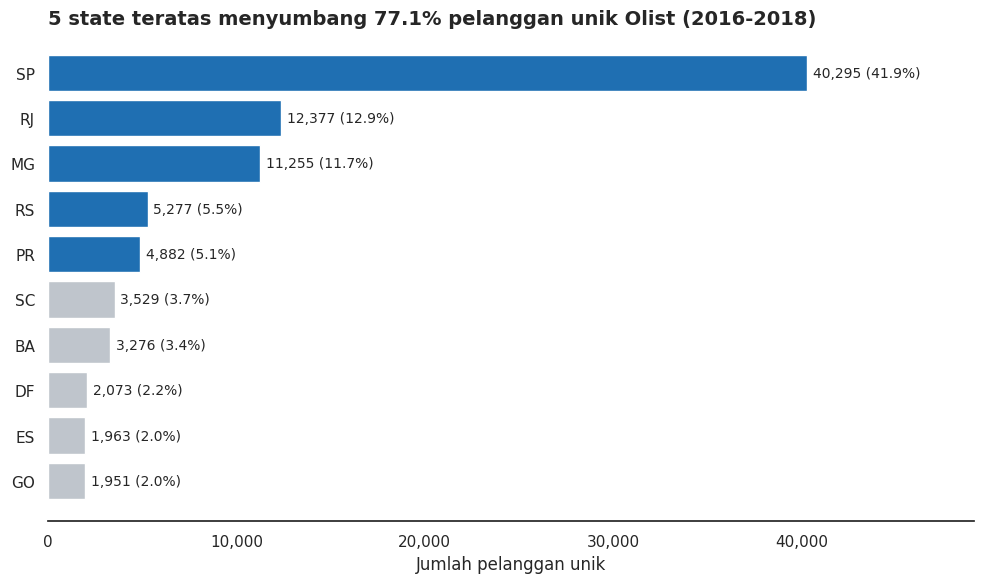

In [84]:
GREY, HIGHLIGHT = "#BFC5CC", "#1F6FB2"
top10_state = state_summary.head(10).iloc[::-1]
colors = [HIGHLIGHT if i >= 5 else GREY for i in range(10)]  # 5 teratas disorot

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top10_state["customer_state"], top10_state["total_customers"], color=colors)
for bar, pct in zip(bars, top10_state["pct"]):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():,.0f} ({pct:.1f}%)", va="center", fontsize=10)
top5_pct = state_summary.head(5)["pct"].sum()
ax.set_title(f"5 state teratas menyumbang {top5_pct:.1f}% pelanggan unik Olist (2016-2018)",
             fontsize=14, loc="left", fontweight="bold")
ax.set_xlabel("Jumlah pelanggan unik")
ax.set_ylabel("")
ax.set_xlim(0, top10_state["total_customers"].max() * 1.22)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Insight:**
- Pelanggan sangat terkonsentrasi di wilayah tenggara dan selatan: SP (41,93%), RJ (12,88%), MG (11,71%), RS (5,49%), dan PR (5,08%) menyumbang total **77,10%**.
- SP saja memiliki jumlah pelanggan lebih dari tiga kali lipat RJ yang berada di posisi kedua.
- Sisa 22 state hanya berbagi sekitar 23% pelanggan.

### **Pertanyaan 2: 10 kota mana dengan pelanggan unik terbanyak, berapa jumlah pelanggan unik tiap kota, dan berapa kontribusinya?**

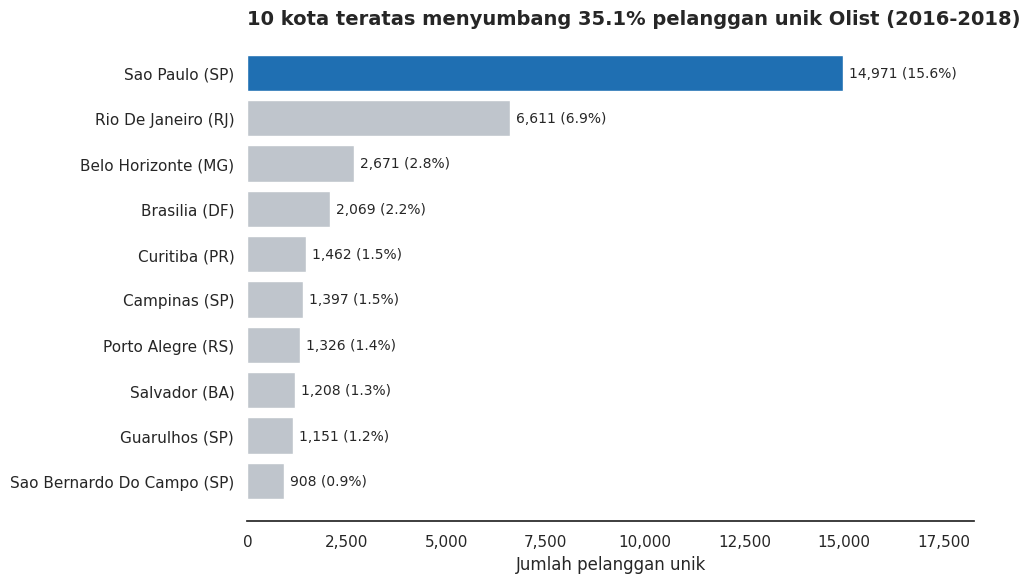

In [85]:
top10_plot = top10_city.iloc[::-1].copy()
labels = (top10_plot["customer_city"].str.title() + " (" + top10_plot["customer_state"] + ")")
colors = [HIGHLIGHT if i == 9 else GREY for i in range(10)]  # kota terbesar disorot

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(labels, top10_plot["total_customers"], color=colors)
for bar, pct in zip(bars, top10_plot["pct"]):
    ax.text(bar.get_width() + 150, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():,.0f} ({pct:.1f}%)", va="center", fontsize=10)
ax.set_title(f"10 kota teratas menyumbang {top10_city['pct'].sum():.1f}% pelanggan unik Olist (2016-2018)",
             fontsize=14, loc="left", fontweight="bold")
ax.set_xlabel("Jumlah pelanggan unik")
ax.set_xlim(0, top10_plot["total_customers"].max() * 1.22)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Insight:**
- 10 kota dengan pelanggan unik terbanyak: Sao Paulo (14.971), Rio de Janeiro (6.611), Belo Horizonte (2.671), Brasilia (2.069), Curitiba (1.462), Campinas (1.397), Porto Alegre (1.326), Salvador (1.208), Guarulhos (1.151), dan Sao Bernardo do Campo (908).
- Total 10 kota ini mencapai 33.774 pelanggan, atau 35,15% dari seluruh pelanggan unik (4.289 kombinasi kota-state). Sisanya tersebar di ribuan kota kecil.
- Sao Paulo (15,58%) dan Rio de Janeiro (6,88%) adalah dua kota dominan, keduanya menyumbang sekitar 22,5% pelanggan.
- Empat dari 10 kota teratas ada di state SP (Sao Paulo, Campinas, Guarulhos, Sao Bernardo do Campo), jadi wilayah metropolitan Sao Paulo sangat penting.

### **Pertanyaan 3: berapa repeat rate tiap region dan region mana yang terendah?**

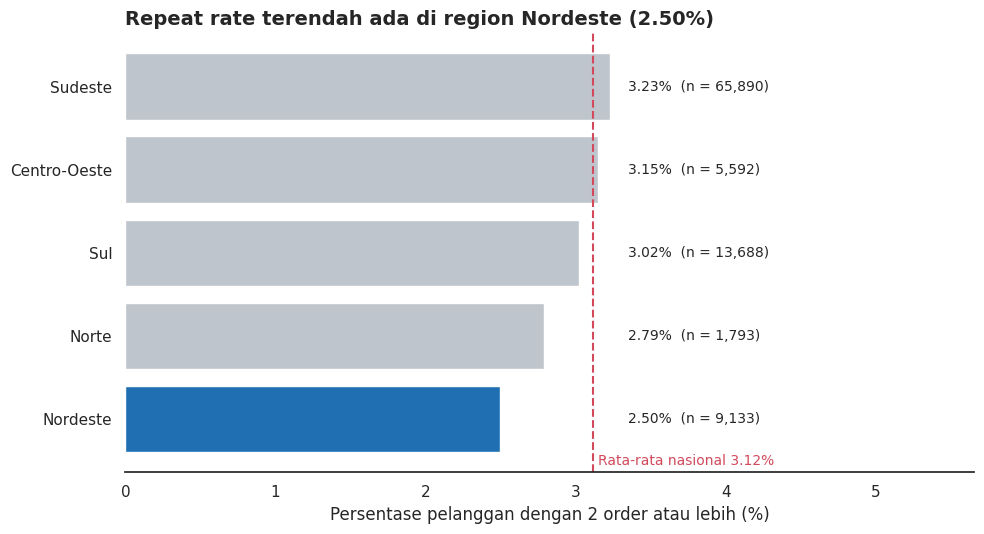

In [86]:
plot_df = region_summary.sort_values("repeat_rate")
lowest = plot_df.iloc[0]["region"]
colors = [HIGHLIGHT if r == lowest else GREY for r in plot_df["region"]]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(plot_df["region"], plot_df["repeat_rate"], color=colors)
label_x = plot_df["repeat_rate"].max() + 0.12  # label sejajar di kolom kanan agar tidak tertimpa garis
for bar, n in zip(bars, plot_df["total_customers"]):
    ax.text(label_x, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.2f}%  (n = {n:,.0f})", va="center", fontsize=10)
ax.axvline(overall_repeat, color="#D1495B", linestyle="--", linewidth=1.5)
ax.text(overall_repeat + 0.03, -0.55, f"Rata-rata nasional {overall_repeat:.2f}%", color="#D1495B", fontsize=10)
ax.set_title(f"Repeat rate terendah ada di region {lowest} ({plot_df.iloc[0]['repeat_rate']:.2f}%)",
             fontsize=14, loc="left", fontweight="bold")
ax.set_xlabel("Persentase pelanggan dengan 2 order atau lebih (%)")
ax.set_xlim(0, plot_df["repeat_rate"].max() * 1.75)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Insight:**
- Repeat rate nasional hanya **3,12%**.
- **Nordeste terendah (2,50%)**, sekitar 0,6 poin persentase di bawah rata-rata nasional. Sudeste tertinggi (3,23%).
- Selisih antar region relatif kecil (0,7 poin persentase), sehingga masalah retensi bersifat **nasional**, dan Nordeste adalah yang paling tertinggal.

## **Analisis Lanjutan**

Dua teknik analisis lanjutan **tanpa algoritma machine learning** diterapkan di sini:

1. **Geospatial Analysis** bertujuan melihat pola persebaran pelanggan berdasarkan lokasi geografis. Setiap state digambarkan sebagai gelembung pada koordinat pusatnya (ukuran = jumlah pelanggan, warna = repeat rate), sehingga konsentrasi pelanggan dan perbedaan repeat rate antarwilayah dapat dilihat dalam satu peta.
2. **Clustering (Manual Grouping & Binning)** bertujuan mengelompokkan data berdasarkan aturan bisnis. *Manual grouping* mengelompokkan 27 state ke dalam 5 region resmi Brasil (Norte, Nordeste, Centro-Oeste, Sudeste, Sul), sedangkan *binning* membagi pelanggan menjadi segmen One-time, Repeat, dan Loyal berdasarkan jumlah order.

> Koordinat yang digunakan adalah perkiraan titik pusat tiap state, bukan lokasi pelanggan yang sebenarnya, sehingga peta ini bersifat indikatif pada tingkat state.

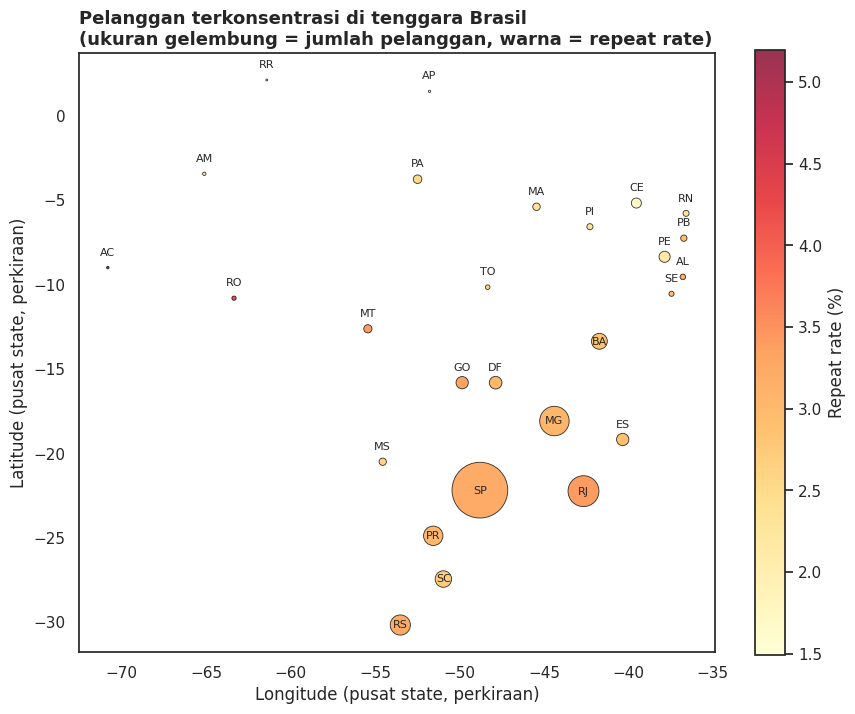

In [87]:
# Geospatial analysis sederhana: bubble map berdasarkan koordinat pusat state
geo_df = (
    unique_customers_df.groupby(["customer_state", "lat", "lon"])
    .agg(total_customers=("customer_unique_id", "nunique"), repeat_rate=("is_repeat", "mean"))
    .reset_index()
)
geo_df["repeat_rate"] *= 100

fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(geo_df["lon"], geo_df["lat"], s=geo_df["total_customers"] / 25,
                c=geo_df["repeat_rate"], cmap="YlOrRd", alpha=0.8, edgecolor="black", linewidth=0.6)
for _, r in geo_df.iterrows():
    dy = 0 if r["total_customers"] > 3000 else 0.9  # label state kecil digeser agar tidak menimpa gelembung
    ax.text(r["lon"], r["lat"] + dy, r["customer_state"], ha="center", va="center", fontsize=8)
cbar = plt.colorbar(sc, ax=ax, shrink=0.7)
cbar.set_label("Repeat rate (%)")
ax.set_title("Pelanggan terkonsentrasi di tenggara Brasil\n(ukuran gelembung = jumlah pelanggan, warna = repeat rate)",
             fontsize=13, loc="left", fontweight="bold")
ax.set_xlabel("Longitude (pusat state, perkiraan)")
ax.set_ylabel("Latitude (pusat state, perkiraan)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

**Insight geospatial:**
- Pelanggan menumpuk di pesisir tenggara (SP, RJ, MG), sedangkan state di utara dan tengah (Amazonas, Roraima, Acre, dll.) sangat kecil.
- Repeat rate antar state cukup bervariasi: dua state Nordeste dengan pelanggan cukup banyak, **Ceara (1,68%)** dan **Pernambuco (2,18%)**, termasuk yang terendah. State kecil seperti Acre (5,19%) dan Rondonia (4,18%) tinggi, tetapi basisnya hanya puluhan sampai ratusan pelanggan sehingga kurang stabil.

In [88]:
# Manual grouping (region) + binning (segmen pelanggan)
segment_region = pd.crosstab(
    unique_customers_df["region"], unique_customers_df["customer_segment"], normalize="index"
) * 100
segment_region.round(2)

customer_segment,One-time (1 order),Repeat (2 order),Loyal (3+ order)
region,,,
Centro-Oeste,96.85,2.90,0.25
Nordeste,97.50,2.30,0.20
Norte,97.21,2.51,0.28
Sudeste,96.77,2.96,0.27
Sul,96.98,2.77,0.26


**Insight binning:** di setiap region, **lebih dari 96%** pelanggan masuk segmen One-time dan hanya **0,20% sampai 0,28%** yang menjadi Loyal (3+ order). Segmen Loyal secara nasional hanya **252 pelanggan**, sehingga basis pelanggan setia masih sangat kecil.

## **Conclusion & Recommendation**

### **Conclusion:**
- **Pertanyaan 1:** 5 state dengan pelanggan unik terbanyak adalah **SP (41,93%), RJ (12,88%), MG (11,71%), RS (5,49%), dan PR (5,08%)**. Kelimanya menyumbang **77,10%** pelanggan Olist pada periode 2016-2018, dengan SP sebagai pusat terbesar.
- **Pertanyaan 2:** 10 kota dengan pelanggan unik terbanyak adalah sebagai berikut. Total kontribusinya **33.774 pelanggan atau 35,15%**, dipimpin Sao Paulo (15,58%) dan Rio de Janeiro (6,88%). Empat dari sepuluh kota ada di state SP.


| No | Kota (State) | Pelanggan unik | Kontribusi |
|---|---|---|---|
| 1 | Sao Paulo (SP) | 14.971 | 15,58% |
| 2 | Rio de Janeiro (RJ) | 6.611 | 6,88% |
| 3 | Belo Horizonte (MG) | 2.671 | 2,78% |
| 4 | Brasilia (DF) | 2.069 | 2,15% |
| 5 | Curitiba (PR) | 1.462 | 1,52% |
| 6 | Campinas (SP) | 1.397 | 1,45% |
| 7 | Porto Alegre (RS) | 1.326 | 1,38% |
| 8 | Salvador (BA) | 1.208 | 1,26% |
| 9 | Guarulhos (SP) | 1.151 | 1,20% |
| 10 | Sao Bernardo do Campo (SP) | 908 | 0,94% |
| | **Total 10 kota** | **33.774** | **35,15%** |


- **Pertanyaan 3:** Repeat rate nasional hanya **3,12%**. Region **Nordeste terendah (2,50%)**, sedangkan Sudeste tertinggi (3,23%). Selisih antar region kecil, sehingga rendahnya pembelian ulang adalah masalah nasional.

### **Recommendation (Action Item):**
1. **Prioritaskan logistik di Sudeste dan Sul:** tempatkan atau perkuat pusat distribusi dan kerja sama kurir di SP, RJ, MG, RS, dan PR yang mencakup 77% pelanggan, dengan SP (khususnya wilayah metropolitan Sao Paulo) sebagai prioritas pertama.
2. **Jalankan kampanye lokal di 10 kota teratas**, dimulai dari Sao Paulo dan Rio de Janeiro, karena kota-kota ini memberi jangkauan pelanggan terbesar per biaya kampanye.
3. **Luncurkan program retensi nasional** (misalnya voucher untuk order kedua) karena 96,88% pelanggan hanya membeli sekali, dengan **Nordeste sebagai region percontohan pertama** karena repeat rate-nya paling rendah (2,50%).
4. **Analisis lanjutan yang disarankan:** gabungkan dengan data order dan pembayaran Olist untuk RFM analysis dan mengukur nilai belanja pelanggan repeat per region.

### **Keterbatasan**
Analisis hanya memakai data pelanggan, sehingga belum mencakup nilai transaksi, produk, atau waktu pembelian. `order_count` dihitung dari jumlah `customer_id` (satu per order), termasuk order yang mungkin dibatalkan.